# 02 - Accuracy assessment

## Setup 

In [1]:
from pathlib import Path
import json, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT   = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA   = ROOT / "data"; FIGDIR = ROOT / "figures"; TABDIR = ROOT / "tables"
FIGDIR.mkdir(exist_ok=True); TABDIR.mkdir(exist_ok=True)

# No constant pixel area is used anywhere below.Area comes from
# STRATA.area_ha, computed in Earth Engine with true spherical cell area,
# which varies slightly with latitude 
CLASSES  = [1, 2, 3]
CLASS_LABEL = {1: "No disturbance", 2: "2015-16 dieback", 3: "Other year"}

# Sampling frame 
STRATA = pd.DataFrame({
    "map_class": CLASSES,
    "N_pixels":  [765132, 29453, 126428],
    "area_ha":   [65762.75, 2522.33, 10855.56],
}).set_index("map_class")
STRATA["W"] = STRATA.N_pixels / STRATA.N_pixels.sum()

TOTAL_HA = STRATA.area_ha.sum()
print(STRATA.round(5).to_string())
print(f"\ntotal {STRATA.N_pixels.sum():,} pixels   {TOTAL_HA:,.1f} ha")

C_DIEBACK, C_REF = "#D55E00", "#0072B2"
C_INK, C_MUTED, C_GRID = "#1a1a1a", "#6b6b6b", "#e0e0e0"
W1, W2 = 3.50, 7.20
plt.rcParams.update({
    "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7,
    "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.edgecolor": C_MUTED, "axes.linewidth": 0.6,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "text.color": C_INK, "axes.labelcolor": C_INK,
    "figure.dpi": 150, "savefig.dpi": 400, "savefig.bbox": "tight"})
def tidy(ax):
    for s in ("top","right"): ax.spines[s].set_visible(False)
    ax.grid(True, color=C_GRID, lw=0.5); ax.set_axisbelow(True); return ax

ACC = {}

           N_pixels   area_ha        W
map_class                             
1            765132  65762.75  0.83075
2             29453   2522.33  0.03198
3            126428  10855.56  0.13727

total 921,013 pixels   79,140.6 ha


## 1. Join the labels to the map

Two files, joined on `point_id`:

* `sample400_blind.csv` — what **naked eye** decided, with no knowledge of the map.
* `sample400_full.csv` — what the **map** claims, plus the stratum.


In [2]:
blind = pd.read_csv(DATA / "sample400_blind.csv")

for _name in ("sample400_full.csv", "s400full.csv"):
    if (DATA / _name).exists():
        full = pd.read_csv(DATA / _name)
        print(f"map-side file: {_name}")
        break
else:
    raise FileNotFoundError(
        "Neither sample400_full.csv nor s400full.csv is in " + str(DATA) +
        ". It is the 400-point file WITH the map_class column.")

ref = blind[["point_id","lon","lat","ref_class","ref_year",
             "ref_confidence","ref_imagery","ref_notes"]].merge(
      full[["point_id","stratum","map_class"]], on="point_id", how="inner",
      validate="one_to_one")

assert (ref.stratum == ref.map_class).all(), \
    "stratum and map_class disagree — the two files are not the same map"

lab = ref[ref.ref_class.notna()].copy()
lab["ref_class"] = lab.ref_class.astype(int)

print(f"points in sample : {len(ref)}")
print(f"points labelled  : {len(lab)}  ({len(lab)/len(ref):.0%})")
print("\nlabelled per stratum:")
prog = (pd.crosstab(ref.map_class, ref.ref_class.notna())
          .rename(columns={False:"unlabelled", True:"labelled"}))
print(prog.to_string())

if len(lab) < len(ref):
    print("\nPartial sample: intervals below are wider than they will be "
          "when labelling is complete. Every estimate is still unbiased.")
ACC["n_labelled"] = int(len(lab)); ACC["n_sample"] = int(len(ref))

map-side file: sample400_full.csv
points in sample : 400
points labelled  : 400  (100%)

labelled per stratum:
ref_class  labelled
map_class          
1               150
2               150
3               100


## 2. The error matrix

Rows are what the **map** says; columns are what **naked eye** found. The diagonal is
agreement. Everything off the diagonal is an error, and which side of the
diagonal it falls on tells you what kind:

* **Off-diagonal across a row** - the map claimed a class that isn't there.
  That is *commission*, and it inflates the mapped area.
* **Off-diagonal down a column** - the map missed something that is there.
  That is *omission*, and it deflates the mapped area.

In [3]:
cm = pd.crosstab(lab.map_class, lab.ref_class).reindex(
        index=CLASSES, columns=CLASSES, fill_value=0)
cm.index.name, cm.columns.name = "Map", "Reference"

cm_out = cm.copy()
cm_out["Total"] = cm_out.sum(axis=1)
cm_out.loc["Total"] = cm_out.sum()
cm_out.to_csv(TABDIR / "table2_error_matrix.csv")
print("Counts (map rows x reference columns)\n")
print(cm_out.to_string())

n_i = cm.sum(axis=1)                 # points labelled per stratum
print("\nraw agreement (not the reported figure):",
      f"{np.diag(cm).sum()/cm.values.sum():.1%}")
if (n_i < 5).any():
    print("\nStrata with fewer than 5 labelled points cannot support an estimate")

Counts (map rows x reference columns)

Reference    1    2   3  Total
Map                           
1          114   10  26    150
2           18  117  15    150
3           57    9  34    100
Total      189  136  75    400

raw agreement (not the reported figure): 66.2%


## 3. Design-based estimation - Olofsson et al. (2014)

**The problem.** 150 of 400 points sit in a class covering 3.2% of the area.
Counting agreement directly would let that class dominate, and the answer would
describe the sample rather than the Gulf.

**The fix.** Convert counts to *estimated area proportions* by weighting each
stratum by its share of the map:

$$\hat p_{ij} = W_i \frac{n_{ij}}{n_{i\cdot}}$$

Every quantity below is built from this matrix, so every quantity refers to the
landscape.

| Quantity | Meaning |
|---|---|
| **User's accuracy** $U_i = \hat p_{ii}/\hat p_{i\cdot}$ | of the area the map calls class *i*, the fraction that really is — what a manager relying on the map experiences |
| **Producer's accuracy** $P_j = \hat p_{jj}/\hat p_{\cdot j}$ | of the area that really is class *j*, the fraction the map found |
| **Overall accuracy** $O = \sum_i \hat p_{ii}$ | area-weighted, not point-weighted |
| **Adjusted area** $\hat A_j = \hat p_{\cdot j} \times A_{total}$ | the estimate that corrects for both commission and omission |

The adjusted area is the headline. If it differs materially from the mapped
area, the mapped figure was biased and the paper must quote the adjusted one.

Standard errors follow Olofsson et al. (2014) equations 5- 7 and 10. The
producer's accuracy variance is the awkward one because the denominator is
itself estimated; it is implemented in full rather than approximated.

In [4]:
W  = STRATA.W.reindex(CLASSES).values
Ni = STRATA.N_pixels.reindex(CLASSES).values.astype(float)
n  = cm.values.astype(float)
ni = n.sum(axis=1)

valid = ni > 1
if not valid.all():
    print("strata with too few labels:", [CLASSES[k] for k in np.where(~valid)[0]])

with np.errstate(divide="ignore", invalid="ignore"):
    prop = n / ni[:, None]                 # n_ij / n_i.
    p    = W[:, None] * prop               # estimated area proportions
p = np.nan_to_num(p)

p_i  = p.sum(axis=1)      # map class share (equals W)
p_j  = p.sum(axis=0)      # reference class share  <- the adjusted areas
diag = np.diag(p)

with np.errstate(divide="ignore", invalid="ignore"):
    U = diag / p_i                         # user's accuracy
    P = diag / p_j                         # producer's accuracy
O = diag.sum()                             # overall accuracy

# standard errors (Olofsson et al. 2014)
# User's accuracy: simple binomial within the stratum (eq 6)
se_U = np.sqrt(U * (1 - U) / (ni - 1))

# Overall accuracy (eq 5)
se_O = np.sqrt(np.nansum(W**2 * U * (1 - U) / (ni - 1)))

# Area proportion of reference class j (eq 10)
se_pj = np.sqrt(np.nansum(
    (W[:, None]**2) * prop * (1 - prop) / (ni[:, None] - 1), axis=0))

# Producer's accuracy (eq 7) - denominator is itself estimated
Nhat_j = (Ni[:, None] * prop).sum(axis=0)
se_P = np.zeros(len(CLASSES))
for j in range(len(CLASSES)):
    t1 = Ni[j]**2 * (1 - P[j])**2 * U[j] * (1 - U[j]) / (ni[j] - 1)
    t2 = P[j]**2 * np.nansum(
        [Ni[i]**2 * prop[i, j] * (1 - prop[i, j]) / (ni[i] - 1)
         for i in range(len(CLASSES)) if i != j])
    se_P[j] = np.sqrt(t1 + t2) / Nhat_j[j]

area_adj    = p_j * TOTAL_HA
area_adj_se = se_pj * TOTAL_HA
area_map    = STRATA.area_ha.reindex(CLASSES).values

table3 = pd.DataFrame({
    "Class": [CLASS_LABEL[c] for c in CLASSES],
    "n labelled": ni.astype(int),
    "Users acc": U, "Users SE": se_U,
    "Producers acc": P, "Producers SE": se_P,
    "Mapped area ha": area_map,
    "Adjusted area ha": area_adj,
    "Adjusted SE ha": area_adj_se,
    "CI95 low ha":  area_adj - 1.96 * area_adj_se,
    "CI95 high ha": area_adj + 1.96 * area_adj_se,
}).round(4)
table3.to_csv(TABDIR / "table3_accuracy.csv", index=False)

print(f"Overall accuracy (area-weighted): {O:.3f}  +/- {1.96*se_O:.3f} (95%)\n")
print(table3.to_string(index=False))

ACC.update({
    "overall_accuracy": float(O), "overall_se": float(se_O),
    "users": {CLASS_LABEL[c]: [float(U[k]), float(se_U[k])] for k,c in enumerate(CLASSES)},
    "producers": {CLASS_LABEL[c]: [float(P[k]), float(se_P[k])] for k,c in enumerate(CLASSES)},
    "area_mapped_ha": {CLASS_LABEL[c]: float(area_map[k]) for k,c in enumerate(CLASSES)},
    "area_adjusted_ha": {CLASS_LABEL[c]: [float(area_adj[k]), float(area_adj_se[k])]
                         for k,c in enumerate(CLASSES)},
})

Overall accuracy (area-weighted): 0.703  +/- 0.058 (95%)

          Class  n labelled  Users acc  Users SE  Producers acc  Producers SE  Mapped area ha  Adjusted area ha  Adjusted SE ha  CI95 low ha  CI95 high ha
 No disturbance         150       0.76    0.0350         0.8850        0.0097        65762.75        56463.0542       2363.9434   51829.7251    61096.3833
2015-16 dieback         150       0.78    0.0339         0.2691        0.0513         2522.33         7334.8555       1382.0651    4626.0079    10043.7031
     Other year         100       0.34    0.0476         0.2407        0.0410        10855.56        15342.7303       2104.3410   11218.2219    19467.2388


In [5]:
k = CLASSES.index(2)
mapped, adj, se = area_map[k], area_adj[k], area_adj_se[k]
bias = adj - mapped

print(f"Mapped area          : {mapped:,.0f} ha")
print(f"Adjusted estimate    : {adj:,.0f} ha  (95% CI {adj-1.96*se:,.0f} - {adj+1.96*se:,.0f})")
print(f"Difference           : {bias:+,.0f} ha  ({bias/mapped:+.1%} of the mapped figure)")
print(f"User's accuracy      : {U[k]:.1%} +/- {1.96*se_U[k]:.1%}")
print(f"Producer's accuracy  : {P[k]:.1%} +/- {1.96*se_P[k]:.1%}")

inside = abs(bias) <= 1.96 * se
print("\nThe mapped area falls "
      + ("inside" if inside else "OUTSIDE")
      + " the 95% interval of the adjusted estimate.")
print("  -> " + ("no evidence of area bias; quote the adjusted figure anyway, "
                 "because it carries the uncertainty."
                 if inside else
                 "the mapped figure is biased."
                 ))

ACC["dieback_statement"] = {
    "mapped_ha": float(mapped), "adjusted_ha": float(adj),
    "ci95": [float(adj-1.96*se), float(adj+1.96*se)],
    "mapped_inside_ci": bool(inside)}

Mapped area          : 2,522 ha
Adjusted estimate    : 7,335 ha  (95% CI 4,626 - 10,044)
Difference           : +4,813 ha  (+190.8% of the mapped figure)
User's accuracy      : 78.0% +/- 6.7%
Producer's accuracy  : 26.9% +/- 10.1%

The mapped area falls OUTSIDE the 95% interval of the adjusted estimate.
  -> the mapped figure is biased.


## 5. Disagreement components sample-based first, then area-based

Kappa is not reported; Pontius & Millones (2011) components are used instead:

* **Quantity** :the map has the wrong *amount* of a class.
* **Allocation** :the right amount in the wrong *place*. Pontius & Santacruz
  (2014) split this further into **exchange** (two classes swapping places) and
  **shift** (the remainder, a one-way drift).

In [6]:
def components(M):
    # quantity, allocation, exchange, shift for any square matrix
    P = M / M.sum()
    pi_, pj_, dg = P.sum(axis=1), P.sum(axis=0), np.diag(P)
    D = 1 - dg.sum()
    Q = np.abs(pi_ - pj_).sum() / 2
    A = D - Q
    K = len(P)
    ex_c = np.array([sum(2 * min(P[g, h], P[h, g]) for h in range(K) if h != g)
                     for g in range(K)])
    E = ex_c.sum() / 2
    return {"total": float(D), "quantity": float(Q), "allocation": float(A),
            "exchange": float(E), "shift": float(A - E),
            "per_class_quantity": np.abs(pi_ - pj_), "per_class_exchange": ex_c,
            "per_class_allocation": 2 * np.minimum(pi_ - dg, pj_ - dg)}

comp_sample = components(n)          # the 400 points as observed
comp_area   = components(p)          # Olofsson area proportions

print(f"{'':22s}{'SAMPLE-BASED':>14s}{'AREA-BASED':>14s}")
for k in ("total", "quantity", "allocation", "exchange", "shift"):
    print(f"{k:22s}{comp_sample[k]:>14.4f}{comp_area[k]:>14.4f}")
for nm_, c_ in (("sample", comp_sample), ("area", comp_area)):
    assert abs(c_["quantity"] + c_["exchange"] + c_["shift"] - c_["total"]) < 1e-9
print("\ncheck passed: quantity + exchange + shift = total, for both")
print(f"exchange share of allocation: sample {comp_sample['exchange']/comp_sample['allocation']:.1%}, "
      f"area {comp_area['exchange']/comp_area['allocation']:.1%}")

# variables used further down
quantity, allocation = comp_area["quantity"], comp_area["allocation"]
exchange, shift = comp_area["exchange"], comp_area["shift"]
q = comp_area["per_class_quantity"]
ACC["disagreement_sample"] = {k: comp_sample[k] for k in
                              ("total", "quantity", "allocation", "exchange", "shift")}
ACC["disagreement"] = {k: comp_area[k] for k in
                       ("total", "quantity", "allocation", "exchange", "shift")}

                        SAMPLE-BASED    AREA-BASED
total                         0.3375        0.2970
quantity                      0.0975        0.1173
allocation                    0.2400        0.1797
exchange                      0.2250        0.1706
shift                         0.0150        0.0092

check passed: quantity + exchange + shift = total, for both
exchange share of allocation: sample 93.7%, area 94.9%


### 5a. 

The design is stratified with equal-ish allocation: 150 / 150 / 100 points,
regardless of how much of the coast each class covers. This is the design
Olofsson et al. (2014) recommend when one class is rare, because otherwise the
rare class would get almost no points. But it means each stratum was sampled
at a very different rate, so the 400 points are not a miniature of the
coastline. The next cell shows how different.

In [7]:
rate = STRATA.N_pixels.reindex(CLASSES).values / ni
share_sample = ni / ni.sum()
share_area = W
print(f"{'map class':18s}{'points':>8s}{'1 point per':>14s}{'share of sample':>17s}{'share of area':>15s}")
for kk, c in enumerate(CLASSES):
    print(f"{CLASS_LABEL[c]:18s}{int(ni[kk]):>8d}{rate[kk]:>11,.0f} px"
          f"{share_sample[kk]:>16.1%}{share_area[kk]:>15.1%}")
over = rate.max() / rate.min()
print(f"\nThe most-sampled stratum is sampled {over:.0f}x more intensely than the least.")

ACC["sampling_rates"] = {CLASS_LABEL[c]: float(rate[kk]) for kk, c in enumerate(CLASSES)}

map class           points   1 point per  share of sample  share of area
No disturbance         150      5,101 px           37.5%          83.1%
2015-16 dieback        150        196 px           37.5%           3.2%
Other year             100      1,264 px           25.0%          13.7%

The most-sampled stratum is sampled 26x more intensely than the least.


### 5b. Per-class components

In [8]:
for nm_, c_ in (("SAMPLE-BASED", comp_sample), ("AREA-BASED", comp_area)):
    print(nm_)
    for kk, c in enumerate(CLASSES):
        print(f"  {CLASS_LABEL[c]:18s} quantity {c_['per_class_quantity'][kk]:.4f}  "
              f"exchange {c_['per_class_exchange'][kk]:.4f}  "
              f"shift {c_['per_class_allocation'][kk]-c_['per_class_exchange'][kk]:.4f}")
    print()

SAMPLE-BASED
  No disturbance     quantity 0.0975  exchange 0.1800  shift 0.0000
  2015-16 dieback    quantity 0.0350  exchange 0.0950  shift 0.0000
  Other year         quantity 0.0625  exchange 0.1750  shift 0.0300

AREA-BASED
  No disturbance     quantity 0.1173  exchange 0.1642  shift 0.0000
  2015-16 dieback    quantity 0.0607  exchange 0.0141  shift 0.0000
  Other year         quantity 0.0566  exchange 0.1629  shift 0.0183



## 6. Direction of confusion - Bradley–Terry (Stein, Aryal & Gort 2005)

**Reporting order**:

1. **Sample-based** - the observed counts, unweighted.
2. **Area-based** - the Olofsson area proportions scaled to the
   sample size (n = 400), justified by the unequal sampling rates in 5a.
3. **Row-standardised** - each map class scaled to 100; shown only as a
   sensitivity check because its standard errors depend on that arbitrary 100.

**Verification.** The fitting code was checked against an independent binomial
GLM (logistic regression on the paired contests), which gives identical
estimates and standard errors.

In [9]:
def bradley_terry(W, ref=0, tol=1e-10, max_iter=20000):
    # Fit Bradley-Terry to a contest matrix W, where W[i,j] counts wins of i
    # over j. Returns log-parameters (reference fixed at 0), asymptotic
    # standard errors from the observed Fisher information, the fitted
    # strengths, and the covariance matrix for pairwise tests.
    k = W.shape[0]
    p = np.ones(k)
    for _ in range(max_iter):
        p_new = np.empty(k)
        for i in range(k):
            num = W[i, :].sum()
            den = sum((W[i, j] + W[j, i]) / (p[i] + p[j])
                      for j in range(k) if j != i)
            p_new[i] = num / den if den > 0 else p[i]
        if p_new[ref] > 0:
            p_new = p_new / p_new[ref]
        if np.max(np.abs(np.log(p_new + 1e-300) - np.log(p + 1e-300))) < tol:
            p = p_new
            break
        p = p_new

    lam = np.log(p) - np.log(p[ref])

    # Fisher information on the log scale; drop the reference parameter
    I = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            if i == j:
                continue
            n = W[i, j] + W[j, i]
            v = n * p[i] * p[j] / (p[i] + p[j]) ** 2
            I[i, i] += v
            I[i, j] -= v
    keep = [i for i in range(k) if i != ref]
    se = np.full(k, np.nan)
    sub = I[np.ix_(keep, keep)]
    V = None
    if len(keep) and np.linalg.matrix_rank(sub) == len(keep):
        V = np.linalg.inv(sub)
        se[keep] = np.sqrt(np.diag(V))
        se[ref] = 0.0
    return lam, se, p, V, keep


def bt_report(Wmat, title):
    Woff = Wmat.astype(float).copy(); np.fill_diagonal(Woff, 0.0)
    if (Woff.sum(axis=1) == 0).any() or (Woff.sum(axis=0) == 0).any():
        print(f"{title}: not enough off-diagonal entries to fit"); return None
    lam, se_bt, p_bt, V, keep = bradley_terry(Woff, ref=0)
    print(title)
    for kk, c in enumerate(CLASSES):
        print(f"  {CLASS_LABEL[c]:18s} score {lam[kk]:+.4f}   SE {se_bt[kk]:.4f}")
    rows_ = []
    for a in range(len(CLASSES)):
        for b in range(a + 1, len(CLASSES)):
            ia = keep.index(a) if a in keep else None
            ib = keep.index(b) if b in keep else None
            var = (V[ib, ib] if ia is None else V[ia, ia] if ib is None
                   else V[ia, ia] + V[ib, ib] - 2 * V[ia, ib])
            sed = np.sqrt(max(var, 0.0)); dab = lam[a] - lam[b]
            z = dab / sed; pv = 2 * (1 - stats.norm.cdf(abs(z)))
            print(f"    {CLASS_LABEL[CLASSES[a]]:16s} vs {CLASS_LABEL[CLASSES[b]]:16s} "
                  f"diff {dab:+.3f}  SE {sed:.3f}  z {z:+.2f}  p {pv:.3f} {'*' if pv < 0.05 else ''}")
            rows_.append(dict(a=CLASS_LABEL[CLASSES[a]], b=CLASS_LABEL[CLASSES[b]],
                              diff=float(dab), ase=float(sed), z=float(z), p=float(pv)))
    print()
    return {"score": [float(v) for v in lam], "se": [float(v) for v in se_bt],
            "pairwise": rows_}

# 6a. standardisation used by Stein, Aryal & Gort (2005)
#
# for the pair of classes (i, j), do not compare the raw off-diagonal counts k1 = n_ij and k2 = n_ji, because the two map classes
# were not sampled at the same rate. Compare the RATES instead,
#
#       r1 = k1 / n_i.      r2 = k2 / n_j.
#       standardised proportion   pi_ij = r1 / (r1 + r2)
#
# and fit  logit(pi_ij) = beta_i - beta_j  by binomial GLM, weighting each pair
# by the number of points it actually contains, k1 + k2. 


def bt_stein(Wmat, row_tot, ref=0, verbose=True):
    """Standardised, weighted Bradley-Terry fit (Stein, Aryal & Gort 2005).

    Wmat     : K x K matrix of counts (rows = map, cols = reference).
    row_tot  : the K row totals n_i. used for standardisation.
    Returns  : lam (scores), se, V (covariance of the free parameters).
    """
    K = Wmat.shape[0]
    Woff = Wmat.astype(float).copy()
    np.fill_diagonal(Woff, 0.0)
    keep = [c for c in range(K) if c != ref]

    rows, y, w = [], [], []
    for i in range(K):
        for j in range(i + 1, K):
            k1, k2 = Woff[i, j], Woff[j, i]
            if k1 + k2 == 0:
                continue
            r1, r2 = k1 / row_tot[i], k2 / row_tot[j]
            if r1 + r2 == 0:
                continue
            x = np.zeros(K); x[i] = 1.0; x[j] = -1.0
            rows.append(x[keep]); y.append(r1 / (r1 + r2)); w.append(k1 + k2)
            if verbose:
                print(f"  {CLASS_LABEL[CLASSES[i]]:18s} vs {CLASS_LABEL[CLASSES[j]]:18s}"
                      f"  k1={k1:5.1f} k2={k2:5.1f}"
                      f"  rates {r1:.4f}/{r2:.4f}"
                      f"  standardised p={r1/(r1+r2):.4f}  weight={k1+k2:.0f}")

    X, y, w = np.array(rows), np.array(y), np.array(w)

    # weighted binomial GLM by iteratively reweighted least squares
    b = np.zeros(X.shape[1])
    for _ in range(200):
        eta = X @ b
        mu = 1.0 / (1.0 + np.exp(-eta))
        v = w * mu * (1.0 - mu)
        z = eta + (y - mu) / np.maximum(mu * (1.0 - mu), 1e-12)
        b_new = np.linalg.solve(X.T @ (v[:, None] * X), X.T @ (v * z))
        if np.max(np.abs(b_new - b)) < 1e-10:
            b = b_new
            break
        b = b_new
    mu = 1.0 / (1.0 + np.exp(-(X @ b)))
    V = np.linalg.inv(X.T @ ((w * mu * (1 - mu))[:, None] * X))

    lam = np.zeros(K); lam[keep] = b
    se = np.zeros(K); se[keep] = np.sqrt(np.diag(V))
    return lam, se, V, keep


print("=" * 72)
print("standardised Bradley-Terry (Stein, Aryal & Gort 2005)")
print("=" * 72)
print("Pairwise standardisation:")
ni_bt = n.sum(axis=1).astype(float)
lam_s, se_s, V_s, keep_s = bt_stein(n, ni_bt, ref=0)

print("\nScores (reference coding, undisturbed = 0):")
for kk, c in enumerate(CLASSES):
    print(f"  {CLASS_LABEL[c]:18s} beta {lam_s[kk]:+.4f}   SE {se_s[kk]:.4f}")
print("  sum-to-zero equivalent:",
      "  ".join(f"{CLASS_LABEL[c]} {v:+.4f}"
               for c, v in zip(CLASSES, lam_s - lam_s.mean())))

print("\nPairwise contrasts (identical under either constraint):")
bt_pairs = []
for a in range(len(CLASSES)):
    for b_ in range(a + 1, len(CLASSES)):
        ia = keep_s.index(a) if a in keep_s else None
        ib = keep_s.index(b_) if b_ in keep_s else None
        var = (V_s[ib, ib] if ia is None else
               V_s[ia, ia] if ib is None else
               V_s[ia, ia] + V_s[ib, ib] - 2 * V_s[ia, ib])
        d = lam_s[a] - lam_s[b_]
        sed = np.sqrt(max(var, 0.0))
        z = d / sed
        pv = 2 * (1 - stats.norm.cdf(abs(z)))
        print(f"  {CLASS_LABEL[CLASSES[a]]:18s} - {CLASS_LABEL[CLASSES[b_]]:18s}"
              f"  diff {d:+.4f}  ASE {sed:.4f}  z {z:+.2f}  p {pv:.3f}"
              f"  {'REJECT H0' if pv < 0.05 else 'not significant'}")
        bt_pairs.append(dict(a=CLASS_LABEL[CLASSES[a]], b=CLASS_LABEL[CLASSES[b_]],
                             diff=float(d), ase=float(sed), z=float(z), p=float(pv)))

bt_stein_res = {"score": [float(v) for v in lam_s],
                "se": [float(v) for v in se_s],
                "score_sum_to_zero": [float(v) for v in (lam_s - lam_s.mean())],
                "pairwise": bt_pairs}


# 6b. 
# p_ij = W_i * n_ij / n_i.  (Olofsson eq. 4), so  p_ij / W_i = n_ij / n_i. .
# The standardised proportion is therefore IDENTICAL whether it is computed
# from the sample counts or from the area proportions. Standardising removes
# the design, so the two weightings can no longer disagree about direction.

print("\n" + "=" * 72)
print("6b. Design-invariance check: sample frame vs area frame")
print("=" * 72)
W_bt = p.sum(axis=1)
for a in range(len(CLASSES)):
    for b_ in range(a + 1, len(CLASSES)):
        r1s, r2s = n[a, b_] / ni_bt[a], n[b_, a] / ni_bt[b_]
        r1a, r2a = p[a, b_] / W_bt[a], p[b_, a] / W_bt[b_]
        ps_, pa_ = r1s / (r1s + r2s), r1a / (r1a + r2a)
        print(f"  {CLASS_LABEL[CLASSES[a]]:18s} vs {CLASS_LABEL[CLASSES[b_]]:18s}"
              f"  sample {ps_:.6f}   area {pa_:.6f}"
              f"   {'IDENTICAL' if abs(ps_ - pa_) < 1e-9 else 'DIFFER'}")
print("\n  The standardised model is invariant to the weighting.")


# 6c. SENSITIVITY

print("\n" + "=" * 72)
print("6c. SENSITIVITY")
print("=" * 72)
bt_sample = bt_report(n, "S1. Unstandardised, observed counts")
bt_area   = bt_report(p * n.sum(), f"S2. Unstandardised, area proportions x {int(n.sum())}")

ACC["bradley_terry"] = {"standardised": bt_stein_res,
                        "unstandardised_sample": bt_sample,
                        "unstandardised_area": bt_area}

pd.DataFrame({
    "Class": [CLASS_LABEL[c] for c in CLASSES],
    "Standardised beta (ref coding)": bt_stein_res["score"],
    "SE": bt_stein_res["se"],
    "Standardised beta (sum-to-zero)": bt_stein_res["score_sum_to_zero"],
    "Unstd. sample": bt_sample["score"] if bt_sample else [np.nan] * len(CLASSES),
    "Unstd. area": bt_area["score"] if bt_area else [np.nan] * len(CLASSES),
}).round(4).to_csv(TABDIR / "table5_bradley_terry.csv", index=False)
print("\nwrote", TABDIR / "table5_bradley_terry.csv")

standardised Bradley-Terry (Stein, Aryal & Gort 2005)
Pairwise standardisation:
  No disturbance     vs 2015-16 dieback     k1= 10.0 k2= 18.0  rates 0.0667/0.1200  standardised p=0.3571  weight=28
  No disturbance     vs Other year          k1= 26.0 k2= 57.0  rates 0.1733/0.5700  standardised p=0.2332  weight=83
  2015-16 dieback    vs Other year          k1= 15.0 k2=  9.0  rates 0.1000/0.0900  standardised p=0.5263  weight=24

Scores (reference coding, undisturbed = 0):
  No disturbance     beta +0.0000   SE 0.0000
  2015-16 dieback    beta +0.8798   SE 0.3144
  Other year         beta +1.0734   SE 0.2313
  sum-to-zero equivalent: No disturbance -0.6511  2015-16 dieback +0.2287  Other year +0.4224

Pairwise contrasts (identical under either constraint):
  No disturbance     - 2015-16 dieback     diff -0.8798  ASE 0.3144  z -2.80  p 0.005  REJECT H0
  No disturbance     - Other year          diff -1.0734  ASE 0.2313  z -4.64  p 0.000  REJECT H0
  2015-16 dieback    - Other year        

## 7. Timing error


The map claims a **year**, not just a class. A point can be correctly called
"disturbed in another year" while the year itself is wrong by a decade, and no
measure built from the class matrix would notice.

Two statistics:

- **proportion within ±1 year** - how often the date is usable
- **median absolute year error** - how wrong it is when it is wrong

Reported alongside quantity and allocation as the third component of total
disagreement.

In [10]:
YEAR_COLS = [c for c in ("db_yod", "hist_yod") if c in full.columns]
if not YEAR_COLS:
    print("no detection-year column in sample400_full.csv - skipping layer 3")
    ACC["timing"] = None
else:
    t = lab.merge(full[["point_id"] + YEAR_COLS], on="point_id", how="left")

    # dieback-run year inside stratum 2, full-history year elsewhere
    if len(YEAR_COLS) == 2:
        t["map_year"] = np.where(t.map_class == 2, t.db_yod, t.hist_yod)
    else:
        t["map_year"] = t[YEAR_COLS[0]]

    # Class 3 carries an explicit reference year. Class 2 means 2015-16 by
    # definition, so it contributes only when the map also says 2015 or 2016.
    ref_eff = np.where(t.ref_class == 3, t.ref_year,
               np.where((t.ref_class == 2) & t.map_year.isin([2015, 2016]),
                        t.map_year, np.nan))
    t["ref_year_eff"] = ref_eff

    miss = t[(t.ref_class == 3) & t.ref_year.isna()]
    if len(miss):
        print(f"*** {len(miss)} class-3 points have no ref_year and are excluded.")
        print("    Layer 3 cannot be computed for them - fill those cells in. ***\n")

    # A map_year of 0 means "no disturbance detected", not year zero. Those
    # points have no date to compare, so they are omission errors for the class
    # matrix  and simply absent from the timing layer.
    valid_year = t.map_year.between(1987, 2025)
    n_nodetect = int((t.ref_class.isin([2, 3]) & ~valid_year).sum())
    if n_nodetect:
        print(f"{n_nodetect} reference-disturbed points have no detection year "
              "(map says undisturbed).")
        

    tt = t[valid_year & t.ref_year_eff.notna()].copy()
    tt["year_err"] = tt.map_year - tt.ref_year_eff

    if len(tt) == 0:
        print("no points yet with both a map year and a reference year.")
        ACC["timing"] = None
    else:
        within1 = float((tt.year_err.abs() <= 1).mean())
        mae = float(tt.year_err.abs().median())
        print(f"points with both years : {len(tt)}")
        print(f"within +/- 1 year      : {within1:.1%}")
        print(f"median absolute error  : {mae:.1f} years")
        print("\nerror distribution (map year minus reference year):")
        print(tt.year_err.value_counts().sort_index().to_string())
        ACC["timing"] = {"n": int(len(tt)), "within_1yr": within1,
                         "median_abs_error_yr": mae,
                         "n_class3_missing_ref_year": int(len(miss)),
                         "n_no_detection_year": n_nodetect}

36 reference-disturbed points have no detection year (map says undisturbed).
points with both years : 166
within +/- 1 year      : 89.2%
median absolute error  : 0.0 years

error distribution (map year minus reference year):
year_err
-6.0       2
-4.0       1
-3.0       2
-2.0       1
-1.0       5
 0.0     143
 2.0       5
 4.0       1
 6.0       1
 12.0      1
 19.0      1
 21.0      1
 22.0      1
 23.0      1


## 10. Figure 5 - mapped versus adjusted area

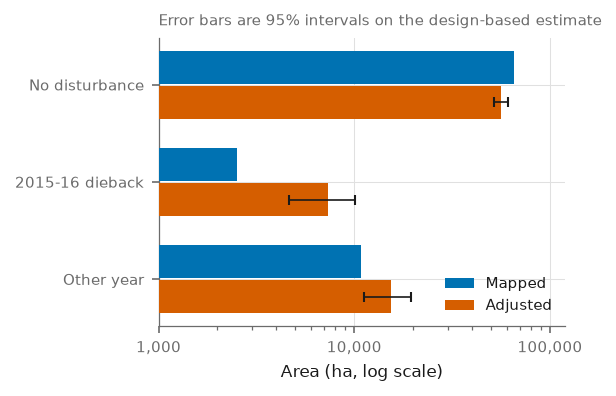


written: tables/table2_error_matrix.csv, tables/table3_accuracy.csv,
         tables/accuracy_summary.json, figures/fig5_area_adjustment.png


In [11]:
fig, ax = plt.subplots(figsize=(W1, 2.5)); tidy(ax)
y = np.arange(len(CLASSES))[::-1]
ax.barh(y + 0.18, area_map, height=0.34, color=C_REF, label="Mapped", zorder=3)
ax.barh(y - 0.18, area_adj, height=0.34, color=C_DIEBACK, label="Adjusted", zorder=3)
ax.errorbar(area_adj, y - 0.18, xerr=1.96*area_adj_se, fmt="none",
            ecolor=C_INK, elinewidth=0.8, capsize=2.5, zorder=4)
ax.set_yticks(y); ax.set_yticklabels([CLASS_LABEL[c] for c in CLASSES])
ax.set_xlabel("Area (ha, log scale)"); ax.set_xscale("log")
# clean log axis: labelled ticks only at 1,000 / 10,000 / 100,000
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
ax.set_xlim(1_000, 120_000)
ax.xaxis.set_major_locator(FixedLocator([1_000, 10_000, 100_000]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.legend(frameon=False, loc="lower right")
ax.set_title("Error bars are 95% intervals on the design-based estimate",
             fontsize=7, color=C_MUTED, loc="left")
fig.savefig(FIGDIR / "fig5_area_adjustment.png"); plt.show()

def clean(o):
    if isinstance(o, dict):  return {k: clean(v) for k,v in o.items()}
    if isinstance(o, list):  return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    return o
with open(TABDIR / "accuracy_summary.json", "w") as f:
    json.dump(clean(ACC), f, indent=2)
print("\nwritten: tables/table2_error_matrix.csv, tables/table3_accuracy.csv,")
print("         tables/accuracy_summary.json, figures/fig5_area_adjustment.png")